In [225]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import matplotlib.pyplot as plt
%matplotlib inline

In [298]:
# hyper parameters, eventually this will come from the harness
batch = 64 # batch size
block = 8 # block size
n_emb = 24 # embedding dimension
n_hidden = 200 # hidden layer size

epochs = 15

# Block size has to be 8 with the current architecture.
# If you want to change it, the pairing in the layers of the model must be updated somehow.
assert block == 8

In [299]:
# Load the data
vocab = set()
names = []
with open('names.txt') as f:
  names = [n.strip()+'.' for n in f.readlines()]
  vocab = set(''.join(names))
  vocab.add('.')
vocab_size = len(vocab)
stoi = {s:i for i,s in enumerate(sorted(vocab))}
itos = {i:s for i,s in enumerate(sorted(vocab))}
assert stoi['.'] == 0, "Somehow our special token got lost"
assert itos[0] == '.', "Somehow our special token got lost"
print(vocab_size)
print(itos)
print(stoi)
print(names[:8])

27
{0: '.', 1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z'}
{'.': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26}
['emma.', 'olivia.', 'ava.', 'isabella.', 'sophia.', 'charlotte.', 'mia.', 'amelia.']


In [300]:
# build datasets

# deterministic shuffle
g = torch.Generator()
g.manual_seed(42)
indices = torch.randperm(len(names), generator=g).tolist()
shuffled = [names[i] for i in indices]

def build_dataset(ns):
  X, Y = [], []
  for n in ns:
    context = [0] * block
    for c in n:
      ix = stoi[c]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]
  return torch.tensor(X), torch.tensor(Y)

training = 80
dev = 10
val = 10
total = training + dev + val
n1 = int(len(shuffled)*training/total)
n2 = int(len(shuffled)*(total-val)/total)

Xtr, Ytr = build_dataset(shuffled[:n1])
Xdev, Ydev = build_dataset(shuffled[n1:n2])
Xval, Yval = build_dataset(shuffled[n2:])

train_set = data.DataLoader(data.TensorDataset(Xtr, Ytr), batch_size=batch, shuffle=True, drop_last=True, num_workers=0, generator=g)
dev_set= data.DataLoader(data.TensorDataset(Xdev, Ydev), batch_size=batch, shuffle=False, drop_last=False, num_workers=0, generator=None)
val_set =data.DataLoader(data.TensorDataset(Xval, Yval), batch_size=batch, shuffle=False, drop_last=False, num_workers=0, generator=None)

In [308]:
# The network
model = nn.Sequential(
  nn.Embedding(vocab_size, n_emb),
  
  nn.Unflatten(1, (block//2, 2)),
  nn.Flatten(start_dim=2),
  nn.Linear(n_emb * 2, n_hidden, bias=False),
  nn.LayerNorm(n_hidden), # momentum = 0.001 would match Karpathy's script
  nn.Tanh(),
  #nn.Dropout(0.2),
  
  nn.Unflatten(1, (block//4, 2)),
  nn.Flatten(start_dim=2),
  nn.Linear(n_hidden * 2, n_hidden, bias=False),
  nn.LayerNorm(n_hidden),
  nn.Tanh(),
  #nn.Dropout(0.2),
  
  nn.Unflatten(1, (block//8, 2)),
  nn.Flatten(start_dim=2),
  nn.Linear(n_hidden * 2, n_hidden, bias=False),
  nn.LayerNorm(n_hidden),
  nn.Tanh(),
  #nn.Dropout(0.2),

  nn.Flatten(),
  nn.Linear(n_hidden, vocab_size),
)

In [309]:
%%time
# training

# probably the most important thing to play with right now
# opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0)
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.0)
total_steps = epochs * len(train_set)
sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[int(total_steps*0.50), int(total_steps*0.75)], gamma=0.1)

model.train()

lossi = []
first = True
for _ in range(epochs):
  for Xb, Yb in train_set:
    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb)
    if first:
      first = False
      print(loss)
    lossi.append(loss.item())
    opt.zero_grad()
    loss.backward()
    opt.step()
    sched.step()

print(f"epochs={epochs}")

tensor(3.2661, grad_fn=<NllLossBackward0>)
epochs=15
CPU times: user 1min 34s, sys: 1min 30s, total: 3min 5s
Wall time: 1min 44s


In [310]:
# eval

@torch.no_grad()
def evaluate(loader):
    model.eval()
    total, count = 0.0, 0
    for Xb, Yb in loader:
        logits = model(Xb)
        total += F.cross_entropy(logits, Yb, reduction='sum').item()
        count += Yb.shape[0]
    model.train()
    return total / count

print(f"train {evaluate(train_set):.4f}  dev {evaluate(dev_set):.4f}")

train 1.8203  dev 1.9944


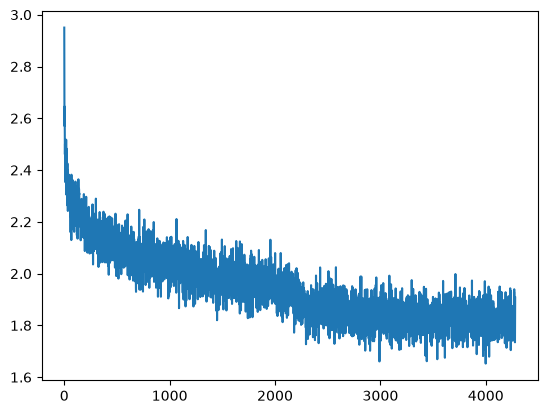

In [311]:
plt.plot(torch.tensor(lossi[:len(lossi)-len(lossi)%100]).view(-1, 10).mean(1))

In [313]:
# Make names
model.eval()

@torch.no_grad()
def make_names(n, temperature=1):
  names = []
  for _ in range(n):
    context = [0] * block
    out = ""
    while True:
      x = torch.tensor([context])
      logits = model(x)
      probs = F.softmax(logits / temperature, dim=-1)
      context = context[1:] + [torch.multinomial(probs, 1).item()]
      if context[-1] != 0:
        out += itos[context[-1]]
      else:
        break
    names.append(out)
  return names

make_names(10)
    

['dafak',
 'arye',
 'onnou',
 'lovanni',
 'alexsia',
 'maelina',
 'zake',
 'thepress',
 'sier',
 'kyreek']